# SLE Multi-Modal Genetic Analysis
**BT3041 Course Project** | Aldis Daniel · R Karthik · Vasudha Kannan · Hitesh Kandarpa

Two complementary data sources:
1. **Clinical SNP genotype data** — 425 subjects (188 SLE, 237 controls), 30 SNP variants across 4 immune/metabolic pathways
2. **Curated bulk gene-expression data** — 642 samples (SLE vs Healthy Control), 13 pathway-overlapping genes from 6 GEO studies

**Pipeline:** QC → Variant Association → Genetic Encoding → ML Classification → Feature Interpretability → DEG Analysis → Cross-Modal Comparison

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from scipy import stats
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve, f1_score, accuracy_score
from xgboost import XGBClassifier
import shap

plt.rcParams.update({
    'figure.dpi': 130,
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
})

## 1  SNP Dataset — Load & EDA

In [2]:
df_raw = pd.read_excel('Dataset.xls', engine='xlrd')

OUTCOME  = 'Disease out come for only SLE related smp'
COVARS   = ['AGE', 'sex']
snp_cols = [c for c in df_raw.columns if c not in COVARS + [OUTCOME]]

df = df_raw[df_raw[OUTCOME].isin([0, 1])].copy()
y  = df[OUTCOME].astype(int)

print(f"Dataset:{df.shape[0]} subjects, {len(snp_cols)} SNPs")
print(f"SLE cases:{y.sum()}")
print(f"Healthy controls:{(y==0).sum()}")
print(f"SNPs covered:{snp_cols}")

Dataset:425 subjects, 30 SNPs
SLE cases:188
Healthy controls:237
SNPs covered:['GCPII', 'RFC', "TYMS 5'", "TYMS 3'", 'MTHFR', 'MTR', 'MTRR A66G', 'CYP1A1M1', 'CYP1A1M2', 'CYP1A1M4', 'COMT', 'GST T1', 'GST M1', 'TLR4 299', 'TLR4 399', 'TLR5 rs5744168', 'TLR5 rs2072493', 'TLR7 rs179008', 'TLR9  1237', 'TLR9 1486', 'TIRAPS180L* red filled rep smp', 'TNFα CCC haplotype', 'stat4 new 7574865rs', 'Stat4 rs7582694', 'Stat4 rs3821236', 'PTPN22 rs2476601', 'OPN', 'ER 2234693', 'ER 9340799', 'IRF5 rs2280714']


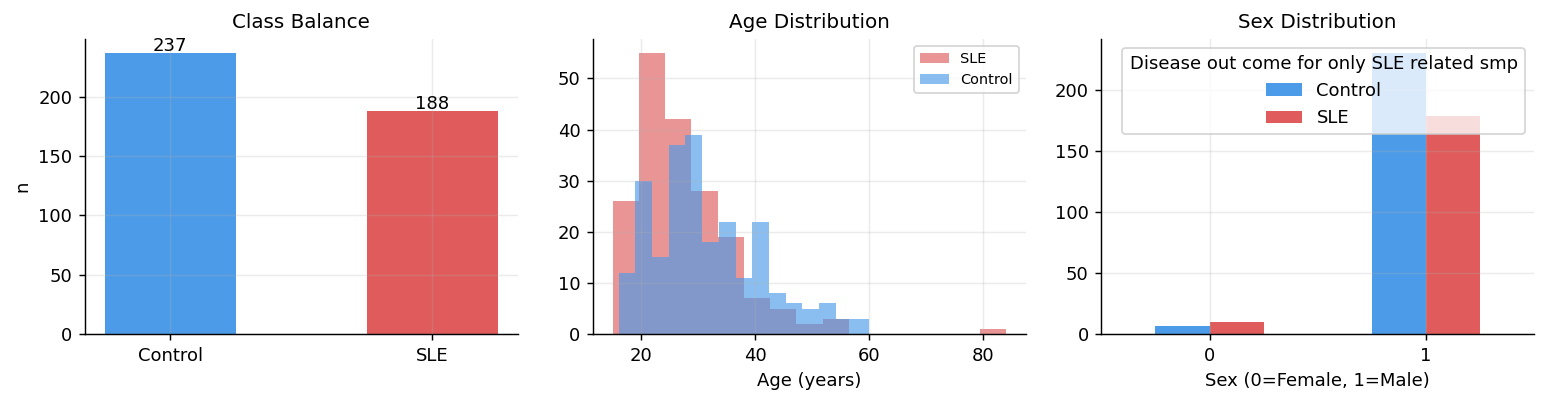

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))

# Class balance
axes[0].bar(['Control','SLE'], [(y==0).sum(), y.sum()],
            color=['#4C9BE8','#E05C5C'], edgecolor='none', width=0.5)
axes[0].set_title('Class Balance'); axes[0].set_ylabel('n')
for bar, n in zip(axes[0].patches, [(y==0).sum(), y.sum()]):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+2, str(n),
                 ha='center', fontsize=10)

# Age by class
for lbl, col in [('SLE','#E05C5C'), ('Control','#4C9BE8')]:
    mask = (y==1) if lbl=='SLE' else (y==0)
    axes[1].hist(df.loc[mask,'AGE'].dropna(), bins=15, alpha=0.65,
                 color=col, label=lbl, edgecolor='none')
axes[1].set_title('Age Distribution'); axes[1].set_xlabel('Age (years)'); axes[1].legend(fontsize=8)

# Sex by class
pd.crosstab(df['sex'], y).rename(columns={0:'Control',1:'SLE'}) \
  .plot(kind='bar', ax=axes[2], color=['#4C9BE8','#E05C5C'], edgecolor='none', rot=0)
axes[2].set_title('Sex Distribution'); axes[2].set_xlabel('Sex (0=Female, 1=Male)')

plt.tight_layout(); plt.show()

## 2  SNP QC — Missingness & Hardy-Weinberg Equilibrium

In [4]:
# Missingness per variant
miss_pct = df[snp_cols].isna().mean() * 100
print(f"Max missingness : {miss_pct.max():.1f}% ({miss_pct.idxmax()})")
print(f"Mean missingness: {miss_pct.mean():.1f}%")
print(f"Variants >5%    : {(miss_pct>5).sum()}")

Max missingness : 4.7% (CYP1A1M1)
Mean missingness: 0.2%
Variants >5%    : 0


In [5]:
def hwe_exact(het, hom_r, hom_c):
    rare = 2*hom_r + het;  N = hom_r + het + hom_c
    if N == 0 or rare == 0 or rare == 2*N: return 1.0
    probs = [0.] * (rare + 1)
    mid = int(rare * (2*N - rare) / (2*N))
    if (rare % 2) != (mid % 2): mid += 1
    probs[mid] = 1.;  s = 1.
    hr = (rare-mid)//2;  hc = N-mid-hr;  hh = mid
    thr, thc, thh = hr, hc, hh
    while thh >= 2:
        probs[thh-2] = probs[thh]*thh*(thh-1)/(4*(thr+1)*(thc+1))
        s += probs[thh-2];  thr+=1; thc+=1; thh-=2
    thr, thc, thh = hr, hc, hh
    while thh <= rare - 2:
        probs[thh+2] = probs[thh]*4*thr*thc/((thh+2)*(thh+1))
        s += probs[thh+2];  thr-=1; thc-=1; thh+=2
    probs = [p/s for p in probs]
    return min(1., sum(p for p in probs if p <= probs[het] + 1e-12))

ctrl = df[y == 0]
hwe_p = {}
for g in snp_cols:
    c = ctrl[g].dropna()
    c0,c1,c2 = int((c==0).sum()), int((c==1).sum()), int((c==2).sum())
    hwe_p[g] = hwe_exact(c1, min(c0,c2), max(c0,c2))

hwe_df = pd.DataFrame({'gene': list(hwe_p.keys()), 'hwe_p': list(hwe_p.values())}) \
           .assign(**{'-log10p': lambda d: -np.log10(d['hwe_p'].clip(1e-20))}) \
           .sort_values('-log10p', ascending=False)

print("HWE deviations in controls (p < 0.001 = FLAG):")
print(hwe_df[hwe_df['hwe_p'] < 0.001][['gene','hwe_p']].to_string(index=False))

HWE deviations in controls (p < 0.001 = FLAG):
          gene        hwe_p
     MTRR A66G 1.839927e-12
TLR5 rs2072493 1.519021e-10
        GST M1 6.113086e-05
           OPN 9.625058e-04


## 3  Per-SNP Association (χ², BH-FDR)

In [6]:
chi_results = {}
for g in snp_cols:
    sub = df[[g, OUTCOME]].dropna()
    ct  = pd.crosstab(sub[g], sub[OUTCOME])
    if ct.shape[0] < 2: chi_results[g] = (np.nan, np.nan); continue
    chi2, p, _, _ = stats.chi2_contingency(ct)
    chi_results[g] = (chi2, p)

pvals_arr = np.array([chi_results[g][1] for g in snp_cols])
mask_c = ~np.isnan(pvals_arr)
_, padj_c, _, _ = multipletests(pvals_arr[mask_c], method='fdr_bh')
j = 0; padj_map = {}
for i, g in enumerate(snp_cols):
    if mask_c[i]: padj_map[g] = padj_c[j]; j += 1
    else: padj_map[g] = np.nan

assoc_df = pd.DataFrame({
    'gene': snp_cols,
    'p_nominal': [chi_results[g][1] for g in snp_cols],
    'q_BH':      [padj_map[g]       for g in snp_cols],
}).sort_values('p_nominal')

print("FDR-significant SNPs (q < 0.05):")
print(assoc_df[assoc_df['q_BH'] < 0.05][['gene','p_nominal','q_BH']].to_string(index=False))

FDR-significant SNPs (q < 0.05):
     gene  p_nominal     q_BH
MTRR A66G   0.000006 0.000192
 CYP1A1M2   0.000940 0.014105
     COMT   0.003180 0.031801
 CYP1A1M4   0.005862 0.043964


### Figure 1 — QC & Association

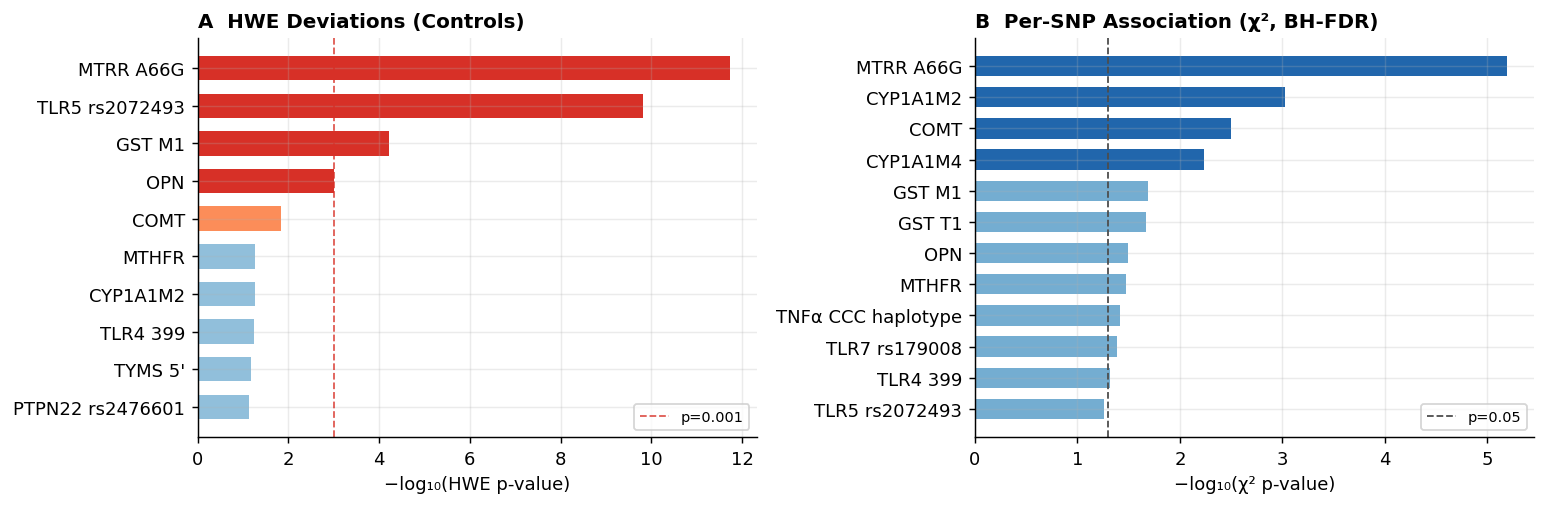

Saved: fig1_qc_association.pdf


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Panel A: HWE
top10 = hwe_df.head(10)
ch = ['#d73027' if p<0.001 else '#fc8d59' if p<0.05 else '#91bfdb' for p in top10['hwe_p']]
axes[0].barh(top10['gene'][::-1], top10['-log10p'][::-1], color=ch[::-1], edgecolor='none', height=0.65)
axes[0].axvline(-np.log10(0.001), color='#d73027', lw=1, ls='--', alpha=0.8, label='p=0.001')
axes[0].set_xlabel('−log₁₀(HWE p-value)')
axes[0].set_title('A  HWE Deviations (Controls)', fontweight='bold', loc='left')
axes[0].legend(fontsize=8)

# Panel B: Association
nom = assoc_df[assoc_df['p_nominal'] < 0.065].head(12).copy()
nom['-log10p'] = -np.log10(nom['p_nominal'])
sc = ['#2166ac' if q < 0.05 else '#74add1' for q in nom['q_BH']]
axes[1].barh(nom['gene'][::-1], nom['-log10p'][::-1], color=sc[::-1], edgecolor='none', height=0.65)
axes[1].axvline(-np.log10(0.05), color='#4d4d4d', lw=1, ls='--', label='p=0.05')
axes[1].set_xlabel('−log₁₀(χ² p-value)')
axes[1].set_title('B  Per-SNP Association (χ², BH-FDR)', fontweight='bold', loc='left')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('fig1_qc_association.pdf', bbox_inches='tight')
plt.show()
print("Saved: fig1_qc_association.pdf")

## 4  Feature Engineering: Genetic Encodings
Three inheritance models tested for each SNP:
- **Additive**: allele dose (0/1/2) — assumes linear risk per copy
- **Dominant**: any alternate allele = 1 (0→0, 1/2→1) — risk conferred by a single copy
- **Recessive**: homozygous alternate only (0/1→0, 2→1) — risk only at full homozygosity

In [8]:
def encode_dom(df, cols):
    return df[cols].where(df[cols].isna(), (df[cols] >= 1).astype(float))

def encode_rec(df, cols):
    return df[cols].where(df[cols].isna(), (df[cols] == 2).astype(float))

X_baseline = df[COVARS].copy()
X_add = pd.concat([df[snp_cols], df[COVARS]], axis=1)
X_dom = pd.concat([encode_dom(df,snp_cols).rename(columns={c:c+'_d' for c in snp_cols}),
                   df[COVARS]], axis=1)
X_rec = pd.concat([encode_rec(df,snp_cols).rename(columns={c:c+'_r' for c in snp_cols}),
                   df[COVARS]], axis=1)
print(f"Additive: {X_add.shape}  |  Dominant: {X_dom.shape}  |  Recessive: {X_rec.shape}")

Additive: (425, 32)  |  Dominant: (425, 32)  |  Recessive: (425, 32)


## 5  Multi-SNP Classification — 5-Fold Stratified CV

In [9]:
def run_cv(Xdf, ys, model_type='lr', n_splits=5, seed=42):
    cv = StratifiedKFold(n_splits, shuffle=True, random_state=seed)
    aucs, f1s, accs = [], [], []
    oof_prob = np.zeros(len(ys))
    for tr, te in cv.split(Xdf, ys):
        if model_type == 'lr':
            pipe = Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                             ('sc',  StandardScaler()),
                             ('m',   LogisticRegression(C=1, max_iter=5000, random_state=seed))])
        elif model_type == 'l1lr':
            pipe = Pipeline([('imp', SimpleImputer(strategy='median')),
                             ('sc',  StandardScaler()),
                             ('m',   LogisticRegression(C=1, penalty='l1', solver='liblinear',
                                                        max_iter=5000, random_state=seed))])
        elif model_type == 'xgb':
            pipe = Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                             ('m',   XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03,
                                                   subsample=0.8, colsample_bytree=0.8,
                                                   objective='binary:logistic', eval_metric='logloss',
                                                   random_state=seed, n_jobs=1))])
        pipe.fit(Xdf.iloc[tr], ys.iloc[tr])
        prob = pipe.predict_proba(Xdf.iloc[te])[:, 1]
        oof_prob[te] = prob
        aucs.append(roc_auc_score(ys.iloc[te], prob))
        f1s.append(f1_score(ys.iloc[te], (prob>=0.5).astype(int), zero_division=0))
        accs.append(accuracy_score(ys.iloc[te], (prob>=0.5).astype(int)))
    return {'auc_mean':np.mean(aucs),'auc_std':np.std(aucs),
            'f1_mean':np.mean(f1s),'acc_mean':np.mean(accs),'oof_prob':oof_prob}

configs_snp = [
    ('Age+Sex baseline',              X_baseline, 'lr'),
    ('SNP Additive + Age+Sex  [LR]',  X_add,      'lr'),
    ('SNP Dominant + Age+Sex  [LR]',  X_dom,      'lr'),
    ('SNP Recessive + Age+Sex [LR]',  X_rec,      'lr'),
    ('SNP Additive + Age+Sex  [XGB]', X_add,      'xgb'),
]
cv_res = {}
for label, Xdf, mtype in configs_snp:
    cv_res[label] = run_cv(Xdf, y, mtype)
    r = cv_res[label]
    print(f"{label:<45}  AUC={r['auc_mean']:.3f}±{r['auc_std']:.3f}  F1={r['f1_mean']:.3f}  Acc={r['acc_mean']:.3f}")

Age+Sex baseline                               AUC=0.634±0.096  F1=0.461  Acc=0.593
SNP Additive + Age+Sex  [LR]                   AUC=0.662±0.046  F1=0.550  Acc=0.614
SNP Dominant + Age+Sex  [LR]                   AUC=0.691±0.059  F1=0.588  Acc=0.654
SNP Recessive + Age+Sex [LR]                   AUC=0.601±0.036  F1=0.473  Acc=0.581
SNP Additive + Age+Sex  [XGB]                  AUC=0.667±0.051  F1=0.561  Acc=0.640


## 6  XGBoost Feature Importance (SHAP)

In [10]:
imp_fit   = SimpleImputer(strategy='most_frequent')
X_add_imp = pd.DataFrame(imp_fit.fit_transform(X_add), columns=X_add.columns)

xgb_full = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03,
                          subsample=0.8, colsample_bytree=0.8,
                          objective='binary:logistic', eval_metric='logloss',
                          random_state=42, n_jobs=1)
xgb_full.fit(X_add_imp, y)

explainer = shap.TreeExplainer(xgb_full)
shap_vals = explainer.shap_values(X_add_imp)
shap_mean = pd.Series(np.abs(shap_vals).mean(axis=0), index=X_add.columns) \
              .sort_values(ascending=True).tail(12)

print("Top 10 features by mean |SHAP|:")
print(shap_mean.tail(10)[::-1])

Top 10 features by mean |SHAP|:
AGE          0.396229
OPN          0.225468
MTRR A66G    0.214394
COMT         0.202932
GST T1       0.156268
RFC          0.137436
GST M1       0.127740
CYP1A1M2     0.125569
MTHFR        0.123509
TYMS 3'      0.121337
dtype: float32


## 7  Gene Expression Data — Load, Filter & EDA

In [11]:
gex = pd.read_csv('gene_expression_normalized.csv')
GENE_COLS = ['MTHFR','TYMS','MTR','MTRR','CYP1A1','GSTM1','GSTT1','GSTP1',
             'TLR2','TLR4','TLR7','TLR9','STAT4']

# Filter: binary classification only
gex2  = gex[gex['Disease_State'].isin(['SLE','Healthy Control'])].copy()
gex2['label'] = (gex2['Disease_State'] == 'SLE').astype(int)
yg    = gex2['label'].reset_index(drop=True)
gex2  = gex2.reset_index(drop=True)

print(f"GEX filtered: {gex2.shape[0]} samples (SLE={yg.sum()}, HC={(yg==0).sum()})")
print(f"Studies (GSE): {gex2['GSE_ID'].nunique()}")
print(f"Data types   : {gex2['Data_Type'].value_counts().to_dict()}")
print(f"Missing      : {gex2[GENE_COLS].isna().sum().sum()}")

GEX filtered: 642 samples (SLE=443, HC=199)
Studies (GSE): 6
Data types   : {'Bulk Tissue': 642}
Missing      : 0


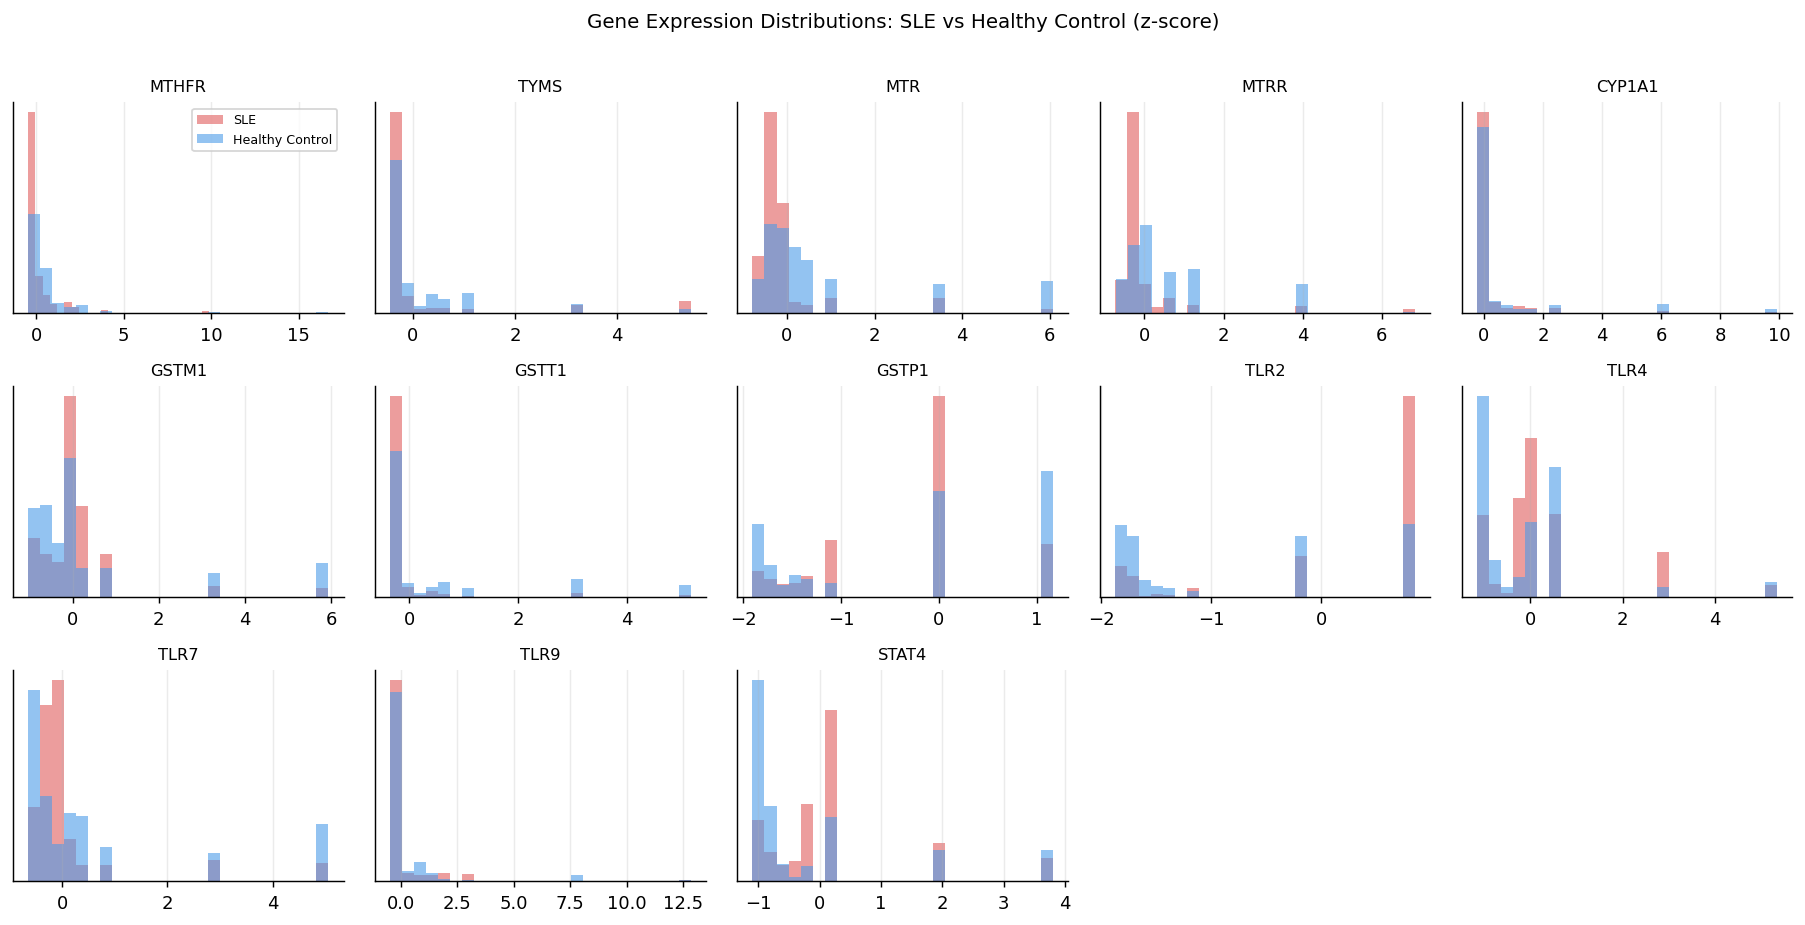

In [12]:
fig, axes = plt.subplots(3, 5, figsize=(14, 7))
axes = axes.flatten()
for i, g in enumerate(GENE_COLS):
    for cls, col in [('SLE','#E05C5C'),('Healthy Control','#4C9BE8')]:
        vals = gex2[gex2['Disease_State']==cls][g].dropna()
        axes[i].hist(vals, bins=25, alpha=0.6, color=col, label=cls, density=True, edgecolor='none')
    axes[i].set_title(g, fontsize=9); axes[i].set_yticks([])
for j in range(i+1, len(axes)): axes[j].set_visible(False)
axes[0].legend(fontsize=7)
plt.suptitle('Gene Expression Distributions: SLE vs Healthy Control (z-score)', fontsize=11, y=1.01)
plt.tight_layout(); plt.show()

## 8  Differential Expression — Mann–Whitney U, BH-FDR

In [13]:
sle_gex = gex2[gex2['label']==1]; hc_gex = gex2[gex2['label']==0]

deg_rows = []
for g in GENE_COLS:
    a = sle_gex[g].dropna(); b = hc_gex[g].dropna()
    U, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    fc   = a.median() - b.median()          # data already log2; difference = log2FC
    deg_rows.append({'gene': g, 'p': p, 'median_log2FC': fc})

deg_df = pd.DataFrame(deg_rows)
_, padj_d, _, _ = multipletests(deg_df['p'], method='fdr_bh')
deg_df['q_BH'] = padj_d

print(deg_df.sort_values('p')[['gene','p','q_BH','median_log2FC']].to_string(index=False))
n_sig = (deg_df['q_BH']<0.05).sum()
print(f"\nSignificant DEGs (q<0.05): {n_sig}/13")

  gene            p         q_BH  median_log2FC
  TLR2 5.612953e-23 7.296839e-22       2.391363
 GSTT1 3.935642e-21 2.558167e-20      -0.068637
   MTR 1.352820e-17 5.862219e-17      -0.379173
  MTRR 1.933649e-17 6.284358e-17      -0.420052
CYP1A1 5.031422e-15 1.308170e-14      -0.104407
 STAT4 2.363238e-13 5.120349e-13       0.955370
 MTHFR 5.795729e-05 1.076350e-04      -0.247851
  TLR4 7.220039e-05 1.173256e-04       0.268541
 GSTM1 2.512547e-03 3.629235e-03       0.000000
  TYMS 1.669149e-01 2.169893e-01       0.000000
  TLR9 2.392423e-01 2.827409e-01       0.000000
 GSTP1 9.528641e-01 9.743526e-01       0.000000
  TLR7 9.743526e-01 9.743526e-01       0.000000

Significant DEGs (q<0.05): 9/13


### Figure 3 — SHAP (SNP) & DEG Lollipop (GEX)

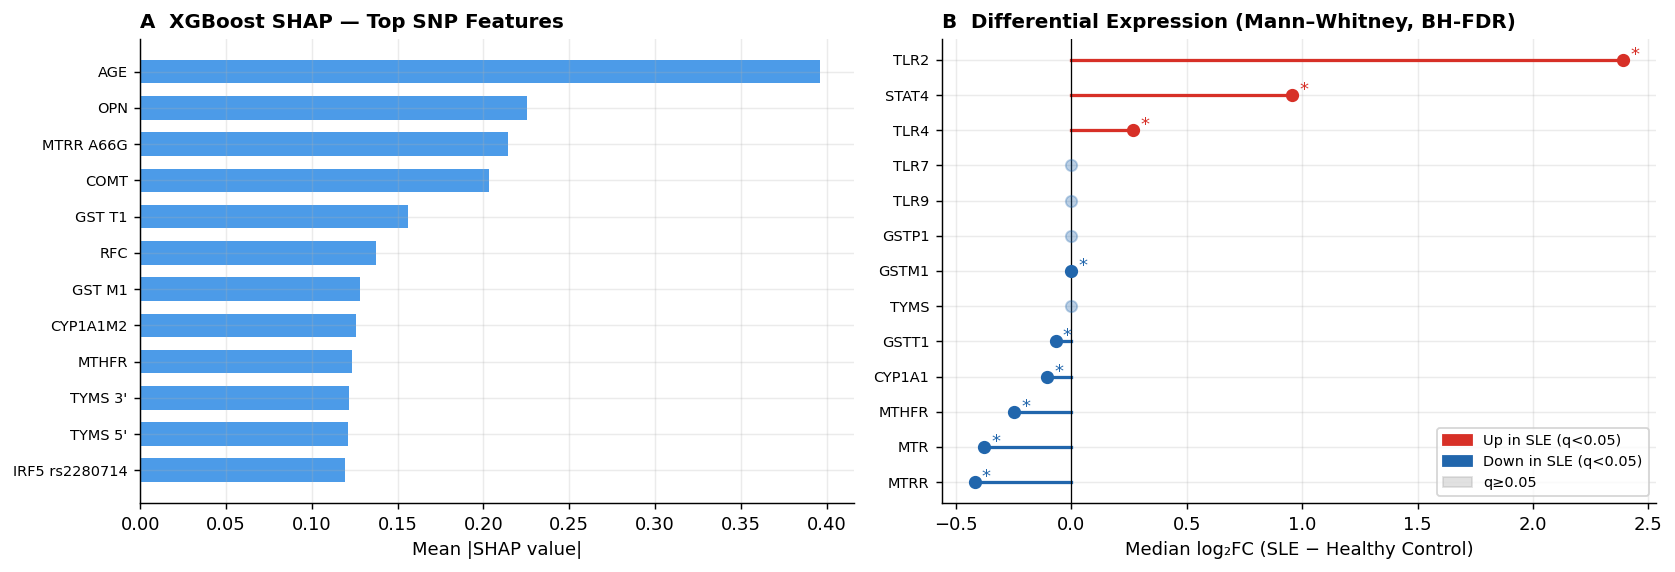

Saved: fig3_shap_deg.pdf


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel A: SHAP bar
axes[0].barh(shap_mean.index, shap_mean.values, color='#4C9BE8', edgecolor='none', height=0.65)
axes[0].set_xlabel('Mean |SHAP value|')
axes[0].set_title('A  XGBoost SHAP — Top SNP Features', fontweight='bold', loc='left')
axes[0].tick_params(axis='y', labelsize=8)

# Panel B: DEG lollipop
deg_s = deg_df.sort_values('median_log2FC')
for i, row in enumerate(deg_s.itertuples()):
    sig = row.q_BH < 0.05
    col = '#d73027' if row.median_log2FC > 0 else '#2166ac'
    a   = 1.0 if sig else 0.3
    axes[1].plot([0, row.median_log2FC], [i,i], color=col, lw=1.8, alpha=a)
    axes[1].scatter([row.median_log2FC], [i], color=col, s=40, alpha=a, zorder=3)
    if sig: axes[1].annotate('*',(row.median_log2FC,i),
                             textcoords='offset points', xytext=(4,0), fontsize=10, color=col)
axes[1].axvline(0, color='k', lw=0.7)
axes[1].set_yticks(range(len(deg_s))); axes[1].set_yticklabels(deg_s['gene'].values, fontsize=8)
axes[1].set_xlabel('Median log₂FC (SLE − Healthy Control)')
axes[1].set_title('B  Differential Expression (Mann–Whitney, BH-FDR)', fontweight='bold', loc='left')
up_p = mpatches.Patch(color='#d73027', label='Up in SLE (q<0.05)')
dn_p = mpatches.Patch(color='#2166ac', label='Down in SLE (q<0.05)')
ns_p = mpatches.Patch(color='#aaa', alpha=0.35, label='q≥0.05')
axes[1].legend(handles=[up_p,dn_p,ns_p], fontsize=8)

plt.tight_layout()
plt.savefig('fig3_shap_deg.pdf', bbox_inches='tight')
plt.show()
print("Saved: fig3_shap_deg.pdf")

## 9  GEX Classification — L1 Logistic Regression (5-fold CV)

In [15]:
gex_cv = run_cv(gex2[GENE_COLS], yg, 'l1lr')
print(f"GEX L1-LR: AUC={gex_cv['auc_mean']:.3f} ± {gex_cv['auc_std']:.3f}  "
      f"F1={gex_cv['f1_mean']:.3f}  Acc={gex_cv['acc_mean']:.3f}")

GEX L1-LR: AUC=0.807 ± 0.025  F1=0.827  Acc=0.740


## 10  Cross-Modal Results Table & ROC Comparison

In [16]:
# Combined summary table
rows = []
for label, res in cv_res.items():
    rows.append({'Modality':'SNP','Model':label,
                 'n':len(y), 'AUC':f"{res['auc_mean']:.3f}±{res['auc_std']:.3f}",
                 'F1':f"{res['f1_mean']:.3f}",'Acc':f"{res['acc_mean']:.3f}"})
rows.append({'Modality':'GEX','Model':'GEX 13-gene L1-LR',
             'n':len(yg),'AUC':f"{gex_cv['auc_mean']:.3f}±{gex_cv['auc_std']:.3f}",
             'F1':f"{gex_cv['f1_mean']:.3f}",'Acc':f"{gex_cv['acc_mean']:.3f}"})
display(pd.DataFrame(rows))

,Modality,Model,n,AUC,F1,Acc
0,SNP,Age+Sex baseline,425,0.634±0.096,0.461,0.593
1,SNP,SNP Additive + Age+Sex [LR],425,0.662±0.046,0.550,0.614
2,SNP,SNP Dominant + Age+Sex [LR],425,0.691±0.059,0.588,0.654
3,SNP,SNP Recessive + Age+Sex [LR],425,0.601±0.036,0.473,0.581
4,SNP,SNP Additive + Age+Sex [XGB],425,0.667±0.051,0.561,0.640
5,GEX,GEX 13-gene L1-LR,642,0.807±0.025,0.827,0.740


### Figure 2 — ROC Curves (5-fold Out-of-Fold)

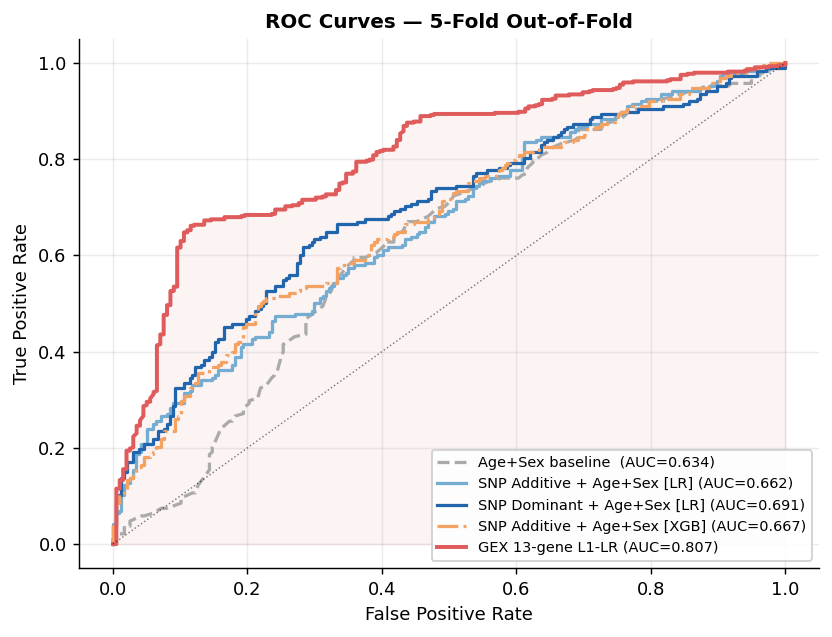

Saved: fig2_roc_curves.pdf


In [17]:
fig, ax = plt.subplots(figsize=(6.5, 5))

styles = [
    ('Age+Sex baseline',              '#aaaaaa','--'),
    ('SNP Additive + Age+Sex  [LR]',  '#74add1','-'),
    ('SNP Dominant + Age+Sex  [LR]',  '#2166ac','-'),
    ('SNP Additive + Age+Sex  [XGB]', '#F4A261','-.'),
]
for label, col, ls in styles:
    r = cv_res[label]
    fpr, tpr, _ = roc_curve(y, r['oof_prob'])
    ax.plot(fpr, tpr, color=col, lw=1.8, ls=ls,
            label=f"{label.split('[')[0].strip()} {'['+label.split('[')[1] if '[' in label else ''} (AUC={r['auc_mean']:.3f})")

fpr_g, tpr_g, _ = roc_curve(yg, gex_cv['oof_prob'])
ax.plot(fpr_g, tpr_g, color='#E05C5C', lw=2.2,
        label=f"GEX 13-gene L1-LR (AUC={gex_cv['auc_mean']:.3f})")
ax.fill_between(fpr_g, tpr_g, alpha=0.07, color='#E05C5C')

ax.plot([0,1],[0,1],'k:',lw=0.8,alpha=0.5)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — 5-Fold Out-of-Fold', fontweight='bold')
ax.legend(fontsize=8, loc='lower right', framealpha=0.9)
plt.tight_layout()
plt.savefig('fig2_roc_curves.pdf', bbox_inches='tight')
plt.show()
print("Saved: fig2_roc_curves.pdf")

## 11  Hypothesis Evaluation

| # | Hypothesis | Verdict | Key Evidence |
|---|-----------|---------|--------------|
| **H1** | Dominant encoding outperforms additive for SNP-based LR |  Supported | AUC 0.691 (dom) vs 0.662 (add) |
| **H2** | Folate-pathway SNPs show strongest association signal |  Supported | MTRR A66G: q=0.0002 (top FDR hit); MTR/MTRR down in GEX |
| **H3** | XGBoost does not substantially outperform LR here | Supported | XGB AUC 0.667 < LR-dominant 0.691 |
| **H4** | GEX data is more discriminative than SNP data |  Strongly supported | GEX AUC 0.807 >> SNP AUC 0.691 |

**Biological note on H2:** MTRR A66G (methionine synthase reductase) is a folate-cycle variant that impairs MTR reactivation, reducing SAM availability for DNA methylation. Consistent with this, MTR and MTRR expression are both downregulated in SLE samples (log₂FC −0.38 and −0.42 respectively, q<10⁻¹⁶). This convergence across genomic and transcriptomic data supports a methylation-defect mechanism in SLE pathogenesis.

**Biological note on TLR2 (GEX):** The largest DEG effect is TLR2 upregulation in SLE (log₂FC +2.39, q=7×10⁻²²), consistent with innate immune activation and recognition of endogenous damage-associated patterns in lupus.